# Sweet Lift Taxi: forecasting airport taxi orders for the next hour

**Ahmad Hassan** | AI Engineer and mentor

**Live app:** [RankCast](https://rankcast-demand-forecast-application.streamlit.app/) · **App code:** [rankcast-demand-forecast-application](https://github.com/ahmadhassan-aiops/rankcast-demand-forecast-application)

Sweet Lift Taxi has six months of taxi orders at an airport and wants to know how many orders the next hour will
bring, so it can call in more drivers before a rush. This notebook resamples the orders to hours, studies the
daily and weekly rhythm, compares simple rules, a seasonal ARIMA and six regression models with time-ordered
cross-validation, measures the chosen model once on the last 10% of the data and saves it for the app.

## Contents

1. Introduction: the task, the data, and an audit of the first version of this notebook
2. Data preparation: hourly orders and the time-ordered split
3. Exploratory analysis: trend, daily and weekly rhythm, stationarity
4. Baselines: what a simple rule achieves
5. Features
6. Model comparison: seven models, time-ordered cross-validation
7. Forecasting further ahead: one model per horizon, 1 to 24 hours
8. The forecast range
9. One test on the held-out hours
10. Saving the model
11. Conclusions

## 1 Introduction

### 1.1 The task

Predict the number of taxi orders at the airport in the next hour. The quality metric is RMSE on a test set made
of the last 10% of the data; the brief requires an RMSE of **48 or less**.

### 1.2 The data

`taxi.csv`: one row per 10 minutes from 1 March to 31 August 2018.

| Column | Meaning |
|---|---|
| `datetime` | start of the 10-minute interval |
| `num_orders` | taxi orders in that interval |

### 1.3 Audit of the first version

The first version of this notebook met the target on paper (LightGBM, test RMSE 42), but the comparison behind it
did not hold:

- **No baseline.** Repeating the orders of the same hour one week earlier scores a test RMSE of **39.5**, better
  than the chosen LightGBM model. A forecasting model is only useful if it beats such a rule.
- **Unequal comparison.** ARIMA and Prophet forecast all 442 test hours (18 days) from the end of the training data,
  while the regression models used the real orders of the previous hours. ARIMA "lost" because it was asked a much
  harder question. Here every model forecasts one hour ahead with the same information.
- **Tuning that was not used.** The ARIMA "search" fitted one fixed guess, (24, 2, 30); the decision tree was tested
  with settings different from the ones the search found, and LightGBM and random forest with their defaults. The
  final model was picked by its test score, so the test set was used for model selection.
- **Features that cannot generalise.** `year` is constant, and `month`, `day` and `quarter` describe a calendar the
  model sees only once in six months. The useful seasonal information (same hour yesterday and last week) was missing:
  the lags stopped at 6 hours.
- **Stationarity misread.** The KPSS test's null hypothesis is that the series *is* stationary; rejecting it (p = 0.01)
  means the series is **not** stationary, the opposite of the conclusion drawn. The trend is plain in the plots.
- Colab paths, `pip` cells and `max_features='auto'` (removed from scikit-learn) stopped the notebook from running.

This version fixes all of these. Prophet is replaced by a seasonal ARIMA scored one hour ahead, so all models answer
the same question.

## 2 Data preparation

In [1]:
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.compose import make_column_transformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3})
SEED = 2023

In [2]:
raw = pd.read_csv("taxi.csv", index_col="datetime", parse_dates=["datetime"]).sort_index()
print(raw.shape, raw.index.min(), "to", raw.index.max())
print("intervals:", raw.index.to_series().diff().value_counts().to_dict())
print("missing values:", int(raw.isna().sum().sum()))
raw.describe().T

(26496, 1) 2018-03-01 00:00:00 to 2018-08-31 23:50:00
intervals: {Timedelta('0 days 00:10:00'): 26495}
missing values: 0


,count,mean,std,min,25%,50%,75%,max
num_orders,26496.0,14.070463,9.21133,0.0,8.0,13.0,19.0,119.0


Every 10-minute interval from 1 March to 31 August 2018 is present, with no gaps and no missing values. (Repeated
order counts are expected in a single count column and are not duplicates.) The task is hourly, so the intervals are
summed per hour.

In [3]:
orders = raw["num_orders"].resample("1h").sum()
orders.name = "orders"
print(len(orders), "hours;", f"mean {orders.mean():.1f}, median {orders.median():.0f}, max {orders.max()} orders per hour")

N_TEST = int(round(len(orders) * 0.1))
test_start = orders.index[-N_TEST]
print("test set:", N_TEST, "hours from", test_start, "to", orders.index[-1])

4416 hours; mean 84.4, median 78, max 462 orders per hour
test set: 442 hours from 2018-08-13 14:00:00 to 2018-08-31 23:00:00


The test set is the last 10% of the hours: **442 hours, 13 August 14:00 to 31 August 23:00**. Nothing from this
period is used for any choice before the final test; all comparisons and tuning use time-ordered cross-validation
on the earlier hours.

## 3 Exploratory analysis

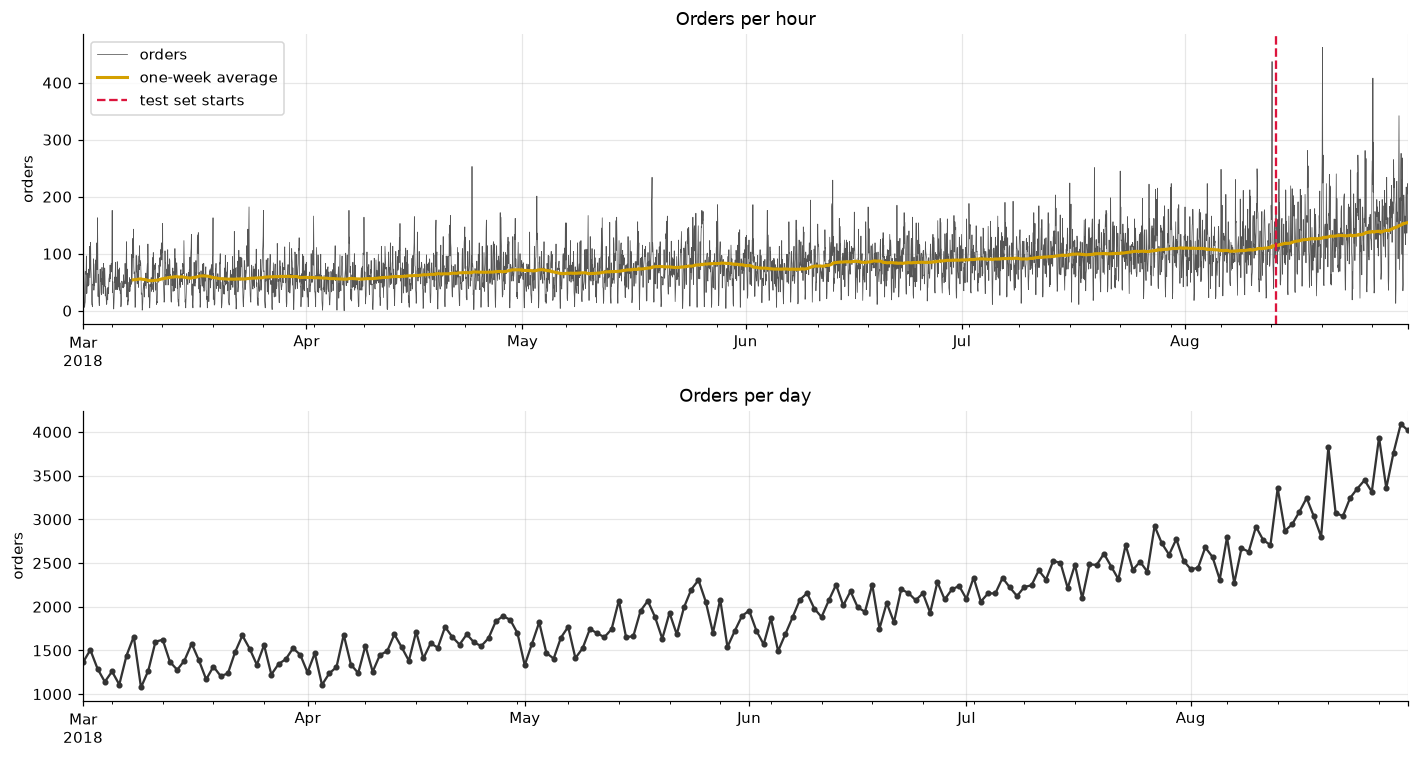

mean orders per hour by month: {3: 57.5, 4: 63.8, 5: 73.7, 6: 83.2, 7: 100.0, 8: 127.7}


In [4]:
daily = orders.resample("1D").sum()
fig, ax = plt.subplots(2, 1, figsize=(13, 7))
orders.plot(ax=ax[0], lw=0.5, color="#555")
orders.rolling(168).mean().plot(ax=ax[0], color="#d4a000", lw=2, label="one-week average")
ax[0].axvline(test_start, color="crimson", ls="--", label="test set starts")
ax[0].set(title="Orders per hour", xlabel="", ylabel="orders"); ax[0].legend()
daily.plot(ax=ax[1], color="#333", marker=".")
ax[1].set(title="Orders per day", xlabel="", ylabel="orders")
plt.tight_layout(); plt.show()

monthly = orders.groupby(orders.index.month).mean()
print("mean orders per hour by month:", monthly.round(1).to_dict())

Demand grows through the whole period: from about 57 orders an hour in March to about 127 in August, with the
steepest rise in the last weeks. The test set therefore sits at the **highest demand level in the data**, above most
of what any model sees in training. A model must follow the current level rather than repeat old averages.

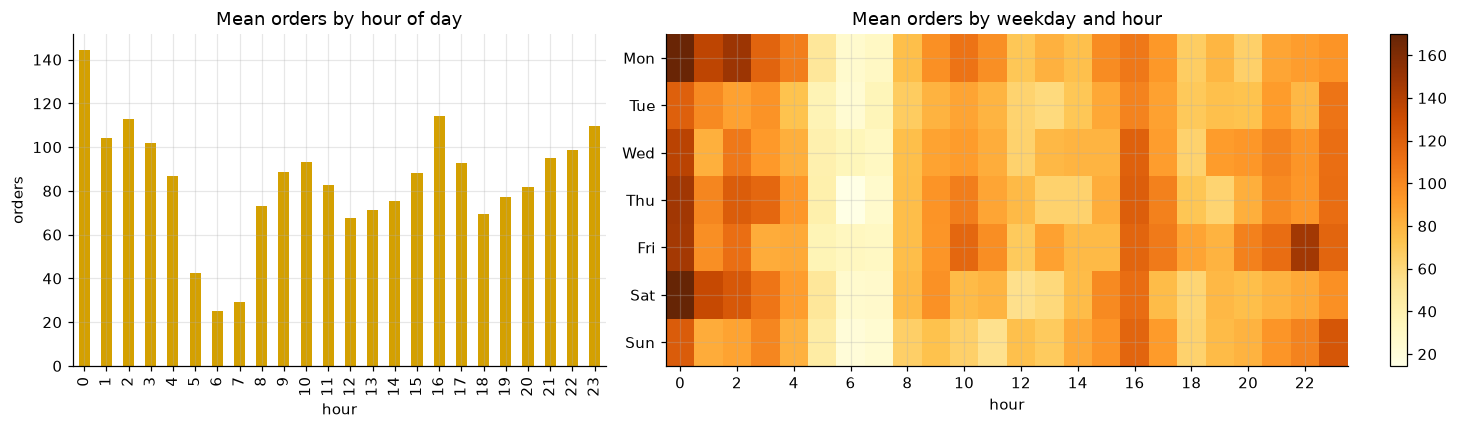

In [5]:
profile = orders.to_frame()
profile["hour"] = profile.index.hour
profile["weekday"] = profile.index.dayofweek
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
heat = profile.pivot_table(index="weekday", columns="hour", values="orders", aggfunc="mean")

fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.6]})
profile.groupby("hour")["orders"].mean().plot.bar(ax=ax[0], color="#d4a000")
ax[0].set(title="Mean orders by hour of day", xlabel="hour", ylabel="orders")
im = ax[1].imshow(heat, aspect="auto", cmap="YlOrBr")
ax[1].set(yticks=range(7), yticklabels=days, xticks=range(0, 24, 2), title="Mean orders by weekday and hour",
          xlabel="hour")
plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()

The day has a strong, repeatable shape: the **busiest hour is midnight** (144 orders on average), demand stays high
until about 4 am, falls to its lowest at **6 am** (25), and climbs again with peaks around 10 am, 4 pm and from 9 pm
(the rhythm of flight arrivals). Mondays and Fridays are the busiest days, Tuesdays the quietest. Both patterns justify hour-of-day,
weekday and same-hour-in-earlier-days features.

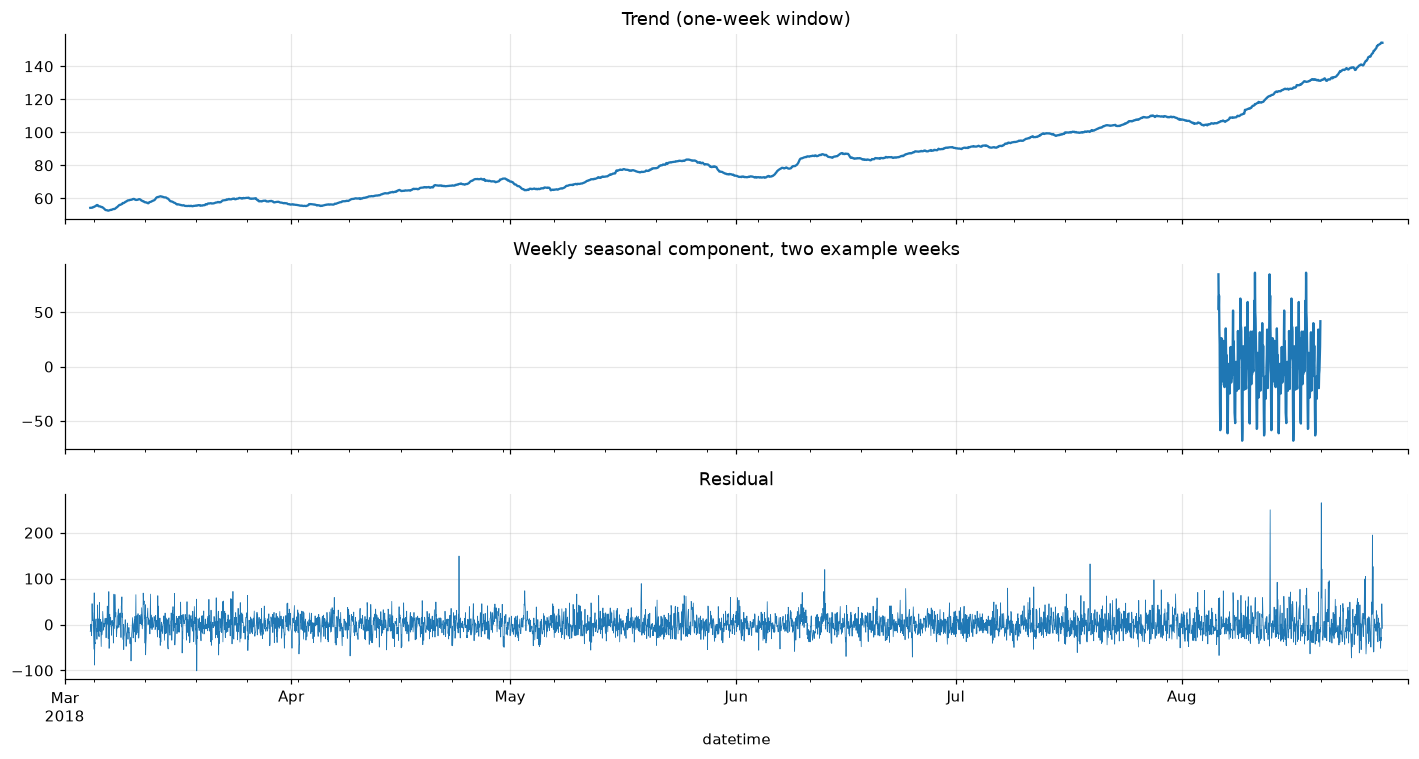

ADF:  statistic -3.07, p = 0.029  (null: the series has a unit root)
KPSS: statistic 10.91, p = 0.010  (null: the series is stationary around a constant mean)


In [6]:
dec = seasonal_decompose(orders, period=24 * 7)
fig, ax = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
dec.trend.plot(ax=ax[0], title="Trend (one-week window)")
dec.seasonal["2018-08-06":"2018-08-19"].plot(ax=ax[1], title="Weekly seasonal component, two example weeks")
dec.resid.plot(ax=ax[2], lw=0.5, title="Residual")
plt.tight_layout(); plt.show()

adf_stat, adf_p = adfuller(orders)[:2]
kpss_stat, kpss_p = kpss(orders, regression="c", nlags="auto")[:2]
print(f"ADF:  statistic {adf_stat:.2f}, p = {adf_p:.3f}  (null: the series has a unit root)")
print(f"KPSS: statistic {kpss_stat:.2f}, p = {kpss_p:.3f}  (null: the series is stationary around a constant mean)")

The two tests answer different questions. ADF rejects a unit root at the 5% level, but KPSS also rejects
stationarity around a constant mean. Together they say the series is **not stationary**: its level rises over time
(the trend above), even though it does not wander like a random walk. Models must therefore work with recent levels
(lags and rolling means) rather than a fixed average, and a differenced ARIMA term is worth trying.

## 4 Baselines

Before any model: how well do simple rules forecast the next hour? Each uses only orders already known.

In [7]:
def rmse(actual, predicted):
    return float(np.sqrt(np.mean((np.asarray(actual, float) - np.asarray(predicted, float)) ** 2)))


tscv = TimeSeriesSplit(n_splits=5)
train_series = orders.iloc[:-N_TEST]
start = 336  # two weeks of history before the first fold, as for the models below
cv_index = np.arange(start, len(train_series))

rules = {
    "Previous hour": orders.shift(1),
    "Same hour yesterday": orders.shift(24),
    "Same hour last week": orders.shift(168),
}
baseline_cv = {}
for name, pred in rules.items():
    scores = []
    for _, val in tscv.split(cv_index):
        idx = train_series.index[cv_index[val]]
        scores.append(rmse(orders[idx], pred[idx]))
    baseline_cv[name] = np.mean(scores)
pd.Series(baseline_cv, name="cross-validated RMSE").round(1).to_frame()

,cross-validated RMSE
Previous hour,37.7
Same hour yesterday,33.0
Same hour last week,26.6


"Same hour last week" is the strongest rule: it carries both the hour-of-day and weekday pattern. It is the bar every
model has to clear.

## 5 Features

For the hour being forecast, the features use only orders known **before** it:

- `hour` and `weekday` (one-hot for the linear models);
- the last six hours (`lag_1` to `lag_6`);
- the same hour 1, 2 and 7 days earlier (`lag_24`, `lag_48`, `lag_168`);
- the mean of the last 24 hours and of the last 168 hours (the current level).

There is no month, day of month or year: with six months of data the model would see each value once and could not
learn anything that holds next month. The first 168 hours have no full week of history and are dropped.

In [8]:
CATEGORICAL = ["hour", "weekday"]


def make_features(series: pd.Series, horizon: int = 1) -> pd.DataFrame:
    """Features for forecasting each hour `horizon` hours ahead: only orders known `horizon` hours earlier."""
    X = pd.DataFrame(index=series.index)
    X["hour"] = series.index.hour
    X["weekday"] = series.index.dayofweek
    recent = range(horizon, horizon + 6)
    for k in recent:
        X[f"lag_{k}"] = series.shift(k)
    for k in (24, 48, 168):
        if k >= horizon and k not in recent:
            X[f"lag_{k}"] = series.shift(k)
    known = series.shift(horizon)
    X["mean_24"] = known.rolling(24).mean()
    X["mean_168"] = known.rolling(168).mean()
    return X


X_all = make_features(orders)
ok = X_all.notna().all(axis=1)
X_all, y_all = X_all[ok], orders[ok]
X_train, y_train = X_all[X_all.index < test_start], y_all[y_all.index < test_start]
X_test, y_test = X_all[X_all.index >= test_start], y_all[y_all.index >= test_start]
print("train", X_train.shape, "test", X_test.shape)
X_train.tail(3)

train (3806, 13) test (442, 13)


,hour,weekday,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_24,lag_48,lag_168,mean_24,mean_168
datetime,,,,,,,,,,,,,
2018-08-13 11:00:00,11,0,156.0,137.0,91.0,39.0,66.0,83.0,81.0,81.0,131.0,137.250000,114.017857
2018-08-13 12:00:00,12,0,144.0,156.0,137.0,91.0,39.0,66.0,123.0,63.0,87.0,139.875000,114.095238
2018-08-13 13:00:00,13,0,92.0,144.0,156.0,137.0,91.0,39.0,120.0,53.0,104.0,138.583333,114.125000


In [9]:
# The lags really are earlier orders: no feature can see the hour it forecasts
t = X_train.index[500]
assert X_train.loc[t, "lag_1"] == orders[t - pd.Timedelta(hours=1)]
assert X_train.loc[t, "lag_168"] == orders[t - pd.Timedelta(hours=168)]
assert np.isclose(X_train.loc[t, "mean_24"], orders[t - pd.Timedelta(hours=24):t - pd.Timedelta(hours=1)].mean())
print("no leakage: lags and means end one hour before the forecast hour")

no leakage: lags and means end one hour before the forecast hour


## 6 Model comparison

Seven models, each scored with the same five time-ordered folds (`TimeSeriesSplit`: every fold trains on the past
and is scored on the following weeks), forecasting one hour ahead:

- Linear regression and ridge regression (one-hot hour and weekday, scaled numbers);
- Random forest, LightGBM, XGBoost and CatBoost (raw features);
- Seasonal ARIMA, refitted on each fold's training hours and then fed the real orders of the validation hours one
  by one, so that it too forecasts one hour ahead.

In [10]:
def linear_pipe(model):
    """One-hot hour and weekday, scale every other column, then the linear model."""
    prep = make_column_transformer((OneHotEncoder(handle_unknown="ignore"), CATEGORICAL), remainder=StandardScaler())
    return make_pipeline(prep, model)


candidates = {
    "Linear regression": lambda: linear_pipe(LinearRegression()),
    "Ridge regression": lambda: linear_pipe(Ridge(alpha=1.0)),
    "Random forest": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    "LightGBM": lambda: LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15, random_state=SEED, verbose=-1),
    "XGBoost": lambda: XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=4, random_state=SEED),
    "CatBoost": lambda: CatBoostRegressor(iterations=600, learning_rate=0.05, depth=6, random_state=SEED, verbose=0),
}

rows = []
for name, make in candidates.items():
    scores, t0 = [], time.perf_counter()
    for tr, va in tscv.split(X_train):
        model = make().fit(X_train.iloc[tr], y_train.iloc[tr])
        scores.append(rmse(y_train.iloc[va], model.predict(X_train.iloc[va])))
    rows.append({"model": name, "cv RMSE": np.mean(scores), "last fold": scores[-1],
                 "seconds": time.perf_counter() - t0})
    print(f"{name:18s} {np.mean(scores):6.2f}")

Linear regression   22.27


Ridge regression    22.19


Random forest       23.11


LightGBM            23.71


XGBoost             23.85


CatBoost            23.77


In [11]:
# Seasonal ARIMA: order chosen by AIC on the first fold among a few candidates, then scored one hour ahead
folds = list(tscv.split(X_train))
first_train = y_train.iloc[folds[0][0]].asfreq("h")
aic = {}
for order, seasonal in [((1, 0, 1), (1, 0, 1, 24)), ((2, 1, 1), (1, 0, 1, 24)), ((1, 1, 1), (1, 0, 1, 24))]:
    aic[(order, seasonal)] = SARIMAX(first_train, order=order, seasonal_order=seasonal).fit(disp=False).aic
best_order, best_seasonal = min(aic, key=aic.get)
print("AIC:", {f"{o}x{s}": round(v) for (o, s), v in aic.items()}, "-> chosen", best_order, best_seasonal)

scores, t0 = [], time.perf_counter()
for tr, va in folds:
    fit = SARIMAX(y_train.iloc[tr].asfreq("h"), order=best_order, seasonal_order=best_seasonal).fit(disp=False)
    va_y = y_train.iloc[va].asfreq("h")
    one_step = fit.append(va_y, refit=False).predict(start=va_y.index[0], end=va_y.index[-1])
    scores.append(rmse(va_y, one_step))
rows.append({"model": f"Seasonal ARIMA {best_order}x{best_seasonal}", "cv RMSE": np.mean(scores),
             "last fold": scores[-1], "seconds": time.perf_counter() - t0})
for name, score in baseline_cv.items():
    rows.append({"model": f"Rule: {name.lower()}", "cv RMSE": score, "last fold": np.nan, "seconds": 0.0})

comparison = pd.DataFrame(rows).set_index("model").sort_values("cv RMSE")
comparison.round(2)

AIC: {'(1, 0, 1)x(1, 0, 1, 24)': 5529, '(2, 1, 1)x(1, 0, 1, 24)': 5537, '(1, 1, 1)x(1, 0, 1, 24)': 5532} -> chosen (1, 0, 1) (1, 0, 1, 24)


,cv RMSE,last fold,seconds
model,,,
Ridge regression,22.19,28.30,0.09
Linear regression,22.27,28.30,0.14
"Seasonal ARIMA (1, 0, 1)x(1, 0, 1, 24)",22.60,29.16,10.76
Random forest,23.11,29.24,5.86
LightGBM,23.71,29.21,3.85
CatBoost,23.77,30.00,8.50
XGBoost,23.85,29.05,2.38
Rule: same hour last week,26.55,NaN,0.00
Rule: same hour yesterday,32.97,NaN,0.00


Every model beats the best rule (same hour last week, 26.6) by a wide margin. Asked the same one-hour-ahead question,
the seasonal ARIMA comes close to the leaders, but it takes minutes to fit and update. The **linear models lead**
(22.2) and are also the fastest; the four tree models trail. This follows from the data: demand keeps rising,
so each validation period sits above most of the training orders. Tree models can only predict values they have seen
in training and fall short in the busiest hours; a linear model scales its forecast with the recent orders. The
ridge version adds a small penalty that keeps the 30-odd weights stable.

### 6.1 Tuning

Ridge regression has one setting, the penalty `alpha`. LightGBM, the best tree model, gets a random search of 20
settings so that it has a fair chance. Both are scored with the same five folds.

In [12]:
alpha_scores = {}
for alpha in np.logspace(-2, 3, 16):
    scores = [rmse(y_train.iloc[va], linear_pipe(Ridge(alpha=alpha)).fit(X_train.iloc[tr], y_train.iloc[tr])
                   .predict(X_train.iloc[va])) for tr, va in folds]
    alpha_scores[alpha] = np.mean(scores)
ALPHA = min(alpha_scores, key=alpha_scores.get)
print(f"best alpha {ALPHA:.3g}: cv RMSE {alpha_scores[ALPHA]:.2f}")

rng = np.random.default_rng(SEED)
lgbm_scores = []
for _ in range(20):
    params = dict(n_estimators=int(rng.integers(200, 1200)), learning_rate=float(rng.uniform(0.01, 0.1)),
                  num_leaves=int(rng.integers(7, 63)), min_child_samples=int(rng.integers(5, 60)),
                  subsample=float(rng.uniform(0.6, 1.0)), subsample_freq=1, colsample_bytree=float(rng.uniform(0.5, 1.0)))
    scores = [rmse(y_train.iloc[va], LGBMRegressor(**params, random_state=SEED, verbose=-1)
                   .fit(X_train.iloc[tr], y_train.iloc[tr]).predict(X_train.iloc[va])) for tr, va in folds]
    lgbm_scores.append((np.mean(scores), params))
best_lgbm = min(lgbm_scores, key=lambda r: r[0])
print(f"LightGBM best of 20 settings: cv RMSE {best_lgbm[0]:.2f}", best_lgbm[1])

best alpha 10: cv RMSE 22.10


LightGBM best of 20 settings: cv RMSE 22.92 {'n_estimators': 438, 'learning_rate': 0.024192762288641832, 'num_leaves': 19, 'min_child_samples': 30, 'subsample': 0.6436344532455852, 'subsample_freq': 1, 'colsample_bytree': 0.9456071017652549}


Ridge improves slightly with `alpha` = 10 (22.1). The tuned LightGBM improves too (22.9) but still trails both
linear models. **Ridge regression is the model**:
the most accurate in cross-validation, trained in a fraction of a second, and readable: each forecast is a sum of
weighted inputs, so the app can show how much the hour of day, the weekday, the last few hours and the same hour
last week each add.

## 7 Forecasting further ahead

Dispatchers plan shifts, not only the next hour. Instead of feeding forecasts back in (which compounds errors), one
ridge model is trained per horizon: the model for *h* hours ahead uses only orders known *h* hours before the target
hour (`make_features(series, horizon=h)`). Each is scored with the same folds (RMSE over all validation hours together).

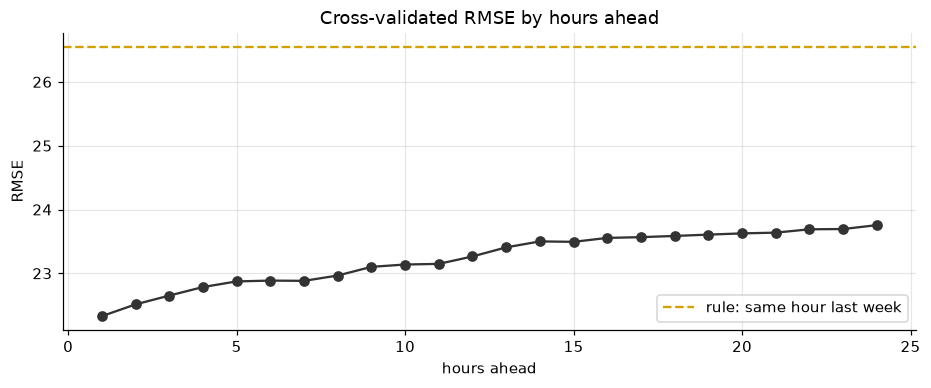

{1: 22.3, 2: 22.5, 3: 22.7, 6: 22.9, 12: 23.3, 24: 23.8}


In [13]:
HORIZONS = range(1, 25)


def horizon_data(h):
    X = make_features(orders, h)
    keep = X.notna().all(axis=1)
    return X[keep], orders[keep]


horizon_cv, oof = {}, {}
for h in HORIZONS:
    X, y = horizon_data(h)
    Xtr, ytr = X[X.index < test_start], y[y.index < test_start]
    pred = pd.Series(np.nan, index=ytr.index)
    for tr, va in tscv.split(Xtr):
        model = linear_pipe(Ridge(alpha=ALPHA)).fit(Xtr.iloc[tr], ytr.iloc[tr])
        pred.iloc[va] = model.predict(Xtr.iloc[va])
    oof[h] = pd.DataFrame({"actual": ytr, "predicted": pred}).dropna()
    horizon_cv[h] = rmse(oof[h]["actual"], oof[h]["predicted"])

ax = pd.Series(horizon_cv).plot(marker="o", figsize=(10, 3.5), color="#333")
ax.axhline(baseline_cv["Same hour last week"], color="#d4a000", ls="--", label="rule: same hour last week")
ax.set(title="Cross-validated RMSE by hours ahead", xlabel="hours ahead", ylabel="RMSE"); ax.legend(); plt.show()
print({h: round(v, 1) for h, v in horizon_cv.items() if h in (1, 2, 3, 6, 12, 24)})

The error grows only slowly with the horizon: the forecast for tomorrow at the same time is barely worse than for
the next hour, because most of the information is in the daily and weekly rhythm and the current level. A full
24-hour plan is therefore usable.

## 8 The forecast range

A single number hides how sure the forecast is. The errors of the cross-validation folds (forecasts on hours the
model had not seen) give a range: for each horizon, the 10th and 90th percentiles of *actual / forecast*. Errors
grow with the level of demand, so a relative range fits better than a fixed number of orders.

In [14]:
RANGE = {}
for h in HORIZONS:
    ratio = oof[h]["actual"] / oof[h]["predicted"].clip(lower=1)
    RANGE[h] = (float(ratio.quantile(0.10)), float(ratio.quantile(0.90)))
print({h: tuple(round(v, 2) for v in RANGE[h]) for h in (1, 6, 24)})

{1: (0.68, 1.36), 6: (0.68, 1.39), 24: (0.69, 1.47)}


For the next hour, 8 in 10 actual counts fell between about 0.68 and 1.36 times the forecast. The test below checks
whether that holds on new hours.

## 9 One test on the held-out hours

The models for every horizon are refitted on all training hours with the chosen setting, and scored once on the 442
test hours.

In [15]:
final, test_rows = {}, []
for h in HORIZONS:
    X, y = horizon_data(h)
    Xtr, ytr = X[X.index < test_start], y[y.index < test_start]
    Xte, yte = X[X.index >= test_start], y[y.index >= test_start]
    final[h] = linear_pipe(Ridge(alpha=ALPHA)).fit(Xtr, ytr)
    pred = final[h].predict(Xte)
    lo, hi = RANGE[h]
    test_rows.append({"hours ahead": h, "RMSE": rmse(yte, pred), "MAE": float(np.mean(np.abs(yte - pred))),
                      "range holds": float(np.mean((yte >= pred * lo) & (yte <= pred * hi)))})
test_by_h = pd.DataFrame(test_rows).set_index("hours ahead")

pred1 = pd.Series(final[1].predict(X_test), index=X_test.index)
TEST = {
    "RMSE": rmse(y_test, pred1), "MAE": float(np.mean(np.abs(y_test - pred1))),
    "range holds": float(test_by_h.loc[1, "range holds"]),
    "rule same hour last week": rmse(y_test, orders.shift(168)[y_test.index]),
    "rule previous hour": rmse(y_test, orders.shift(1)[y_test.index]),
}
print({k: round(v, 3) for k, v in TEST.items()})
test_by_h.loc[[1, 2, 3, 6, 12, 24]].round(3)

{'RMSE': 34.767, 'MAE': 25.765, 'range holds': 0.817, 'rule same hour last week': 39.549, 'rule previous hour': 58.856}


,RMSE,MAE,range holds
hours ahead,,,
1,34.767,25.765,0.817
2,35.241,26.149,0.828
3,35.344,26.158,0.830
6,35.287,26.060,0.848
12,35.582,26.342,0.846
24,35.476,26.054,0.867


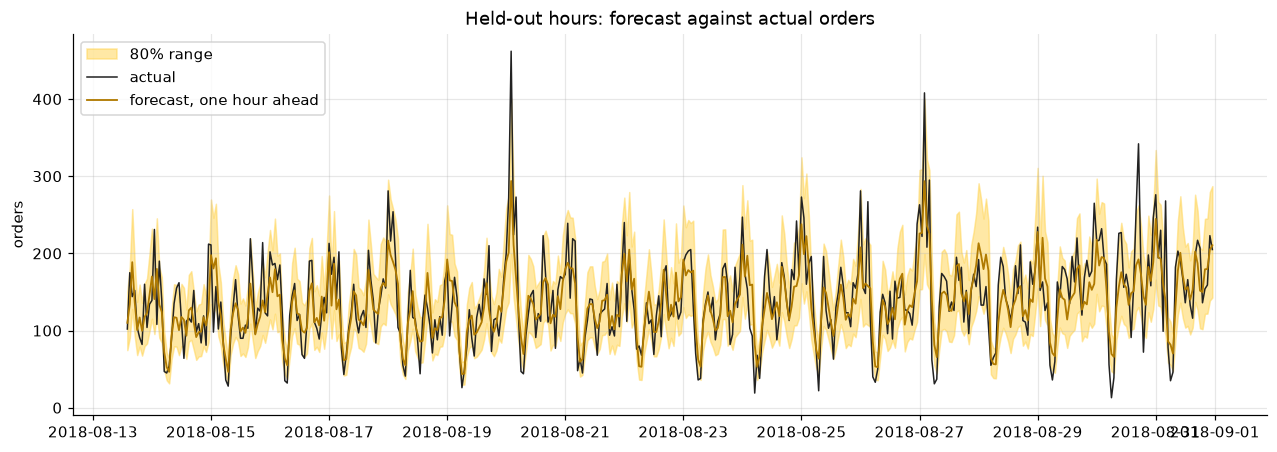

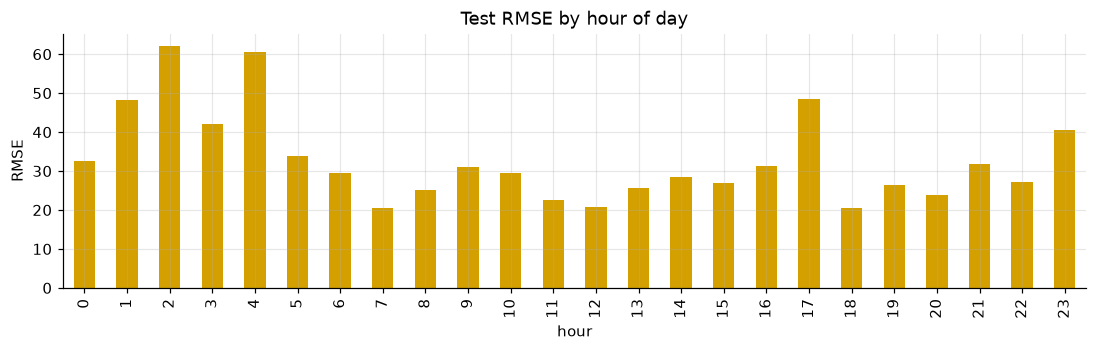

In [16]:
lo, hi = RANGE[1]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.fill_between(pred1.index, pred1 * lo, pred1 * hi, color="#ffd34d", alpha=0.5, label="80% range")
ax.plot(y_test.index, y_test, color="#222", lw=1, label="actual")
ax.plot(pred1.index, pred1, color="#b07a00", lw=1.2, label="forecast, one hour ahead")
ax.set(title="Held-out hours: forecast against actual orders", ylabel="orders"); ax.legend(loc="upper left")
plt.show()

err = (y_test - pred1).groupby(y_test.index.hour).apply(lambda e: float(np.sqrt(np.mean(e ** 2))))
err.plot.bar(figsize=(12, 3), color="#d4a000", title="Test RMSE by hour of day", xlabel="hour", ylabel="RMSE")
plt.show()

The forecast follows the daily rhythm and the late-August rise. The largest errors fall in the late-night hours,
the busiest and most irregular part of the day (flight delays move whole waves of passengers), where the range is
also widest.

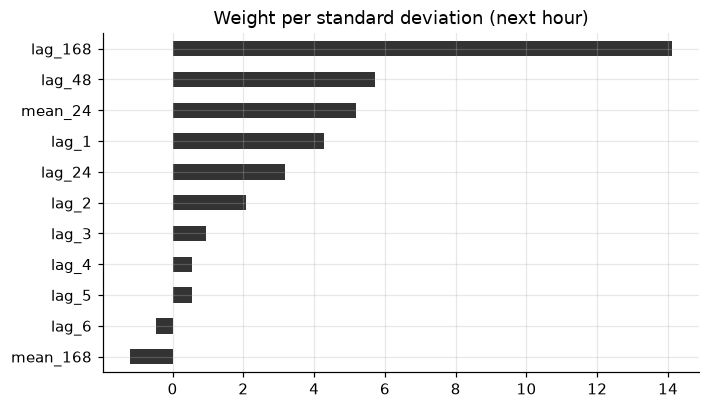

In [17]:
# Which inputs carry the next-hour forecast: weights of the scaled numbers
ridge = final[1][-1]
names = final[1][0].get_feature_names_out()
coef = pd.Series(ridge.coef_, index=names)
num = coef[[n.startswith("remainder") for n in names]].rename(lambda n: n.split("__")[1])
num.sort_values().plot.barh(figsize=(7, 4), color="#333", title="Weight per standard deviation (next hour)")
plt.show()

The same hour last week carries the most weight, followed by the same hour two days ago, the mean of the last
24 hours and the previous hour. The 7-day mean and the order count six hours earlier get small negative weights:
the inputs overlap, so once the others are known they only correct. Hour of day and weekday (not shown) shape the
forecast around this level.

## 10 Saving the model

The 24 fitted pipelines (one per horizon), the range ratios and the evaluation figures are saved for the app. The
app reproduces them with `train.py`.

In [18]:
out = Path("model")
out.mkdir(exist_ok=True)
joblib.dump({h: final[h] for h in HORIZONS}, out / "rankcast_ridge.joblib", compress=3)
meta = {
    "model": "Ridge regression, one per horizon (1 to 24 hours)", "alpha": ALPHA,
    "train_hours": int(len(X_train)), "test_hours": int(len(X_test)),
    "train_end": str(X_train.index[-1]), "test_start": str(test_start), "test_end": str(orders.index[-1]),
    "features": list(X_train.columns), "range": {str(h): RANGE[h] for h in HORIZONS},
    "cv": {k: float(v) for k, v in comparison["cv RMSE"].items()},
    "cv_by_horizon": {str(h): float(v) for h, v in horizon_cv.items()},
    "test": TEST, "test_by_horizon": {str(h): r for h, r in test_by_h.to_dict("index").items()},
}
(out / "metadata.json").write_text(json.dumps(meta, indent=2))
reloaded = joblib.load(out / "rankcast_ridge.joblib")
assert np.allclose(reloaded[1].predict(X_test), pred1)
print("saved and verified:", sorted(p.name for p in out.iterdir()))

saved and verified: ['metadata.json', 'rankcast_ridge.joblib']


## 11 Conclusions

**Data.** 26,496 ten-minute counts (1 March to 31 August 2018, no gaps) summed to 4,416 hours. Demand more than
doubles over the six months, and each day follows the same rhythm: busiest at midnight, quietest at 6 am. The series
is not stationary (KPSS), so models must work from recent levels.

**Models.** On five time-ordered folds, every model beat the best simple rule (same hour last week), and ridge
regression was the most accurate, ahead of a seasonal ARIMA and four tree models. Tree models fall short because the
rising demand keeps moving above the values they were trained on.

**One test on 442 held-out hours** (13 to 31 August, the busiest weeks in the data):

| Forecast | Test RMSE | MAE | 80% range holds |
|---|---|---|---|
| **Ridge, next hour** | **34.8** | 25.8 | 81.7% |
| Ridge, 6 hours ahead | 35.3 | 26.1 | 84.8% |
| Ridge, 24 hours ahead | 35.5 | 26.1 | 86.7% |
| Rule: same hour last week | 39.5 | | |
| Rule: previous hour | 58.9 | | |

The next-hour RMSE of 34.8 is well inside the brief's limit of 48 and 12% better than the best rule. Test errors are
larger than in cross-validation (22.1) because demand in late August is the highest in the data, and errors grow with
demand: relative to the orders, the test error is similar.

**Recommendation for Sweet Lift.** Use the ridge models to plan drivers a day ahead and to adjust each hour, and plan
for the top of the range in the late-night hours. Retrain often: demand was still rising at the end of the data, and
a model trained on old levels will fall behind. The model is live in the
[RankCast app](https://rankcast-demand-forecast-application.streamlit.app/).